In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")


Preprocessing

In [49]:
df = pd.read_excel("/content/online_retail_II.xlsx")

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [50]:
print("Rows and columns:", df.shape)

df.info()

Rows and columns: (1067371, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB


In [51]:
df.describe()

,Quantity,Price,Customer ID
count,1.067371e+06,1.067371e+06,824364.000000
mean,9.938898e+00,4.649388e+00,15324.638504
std,1.727058e+02,1.235531e+02,1697.464450
min,-8.099500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13975.000000
50%,3.000000e+00,2.100000e+00,15255.000000
75%,1.000000e+01,4.150000e+00,16797.000000
max,8.099500e+04,3.897000e+04,18287.000000


In [52]:
print("Missing values:\n", df.isnull().sum())


Missing values:
 Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


In [53]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 34335


In [54]:
df = df.dropna()

In [55]:
df = df.drop_duplicates()

In [56]:
df.shape

(797885, 8)

In [57]:

print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


In [58]:
df["TotalAmount"] = df["Quantity"] * df["Price"]

rfm score

In [59]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

df = df.dropna(subset=["InvoiceDate"]).copy()

df["TotalAmount"] = df["Quantity"] * df["Price"]

reference_date = (
    df["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

rfm = df.groupby("Customer ID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("TotalAmount", "sum")
)

rfm["Recency"] = (
    reference_date - rfm["LastPurchase"]
).dt.days

rfm = rfm[["Recency", "Frequency", "Monetary"]].copy()

print("Reference date:", reference_date)
print("Customer-level RFM shape:", rfm.shape)
rfm.head()

Reference date: 2011-12-10 00:00:00
Customer-level RFM shape: (5942, 3)


,Recency,Frequency,Monetary
Customer ID,,,
12346.0,325,17,-51.74
12347.0,2,8,4921.53
12348.0,75,5,2019.40
12349.0,18,5,4404.54
12350.0,310,1,334.40


In [60]:
rfm.describe().round(2)

,Recency,Frequency,Monetary
count,5942.00,5942.00,5942.00
mean,202.46,7.55,2741.50
std,211.88,15.97,13676.64
min,0.00,1.00,-25111.09
25%,24.00,2.00,321.06
50%,95.50,4.00,822.01
75%,381.00,8.00,2142.19
max,738.00,510.00,570380.61


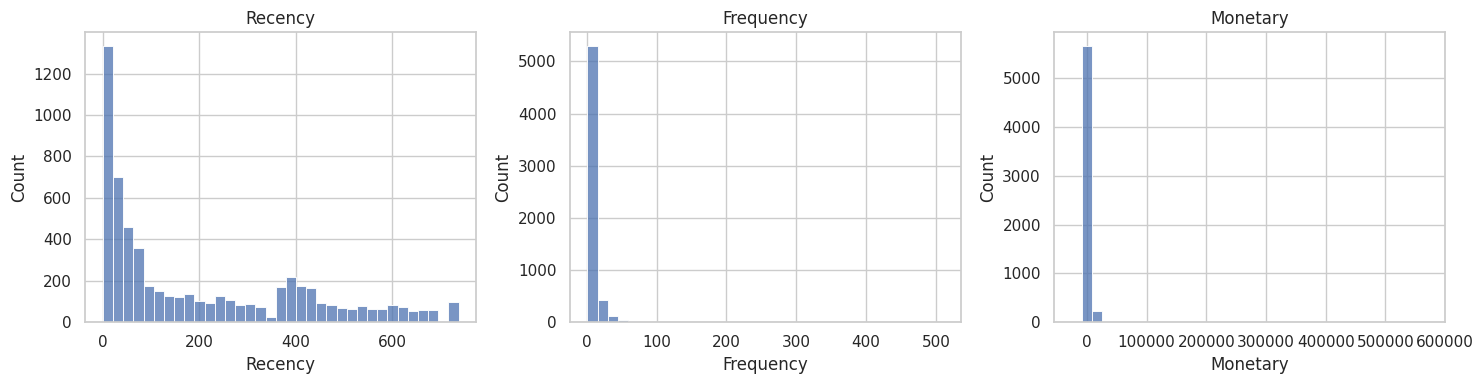

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[column], bins=35, ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()

K means cluster

In [62]:

features = rfm[["Recency", "Frequency", "Monetary"]].copy()


features = features.replace([np.inf, -np.inf], np.nan)


features = features.dropna()


features = features[(features >= 0).all(axis=1)]


rfm = rfm.loc[features.index].copy()

print("RFM shape after cleaning:", features.shape)
print("Missing values:\n", features.isnull().sum())
print("Negative values:\n", (features < 0).sum())

features_log = np.log1p(features)

scaler = StandardScaler()
features_scaled = scaler.fit_transform(features_log)

print("Scaled data shape:", features_scaled.shape)
print("Contains NaN:", np.isnan(features_scaled).any())
print("Contains infinity:", np.isinf(features_scaled).any())

RFM shape after cleaning: (5858, 3)
Missing values:
 Recency      0
Frequency    0
Monetary     0
dtype: int64
Negative values:
 Recency      0
Frequency    0
Monetary     0
dtype: int64
Scaled data shape: (5858, 3)
Contains NaN: False
Contains infinity: False


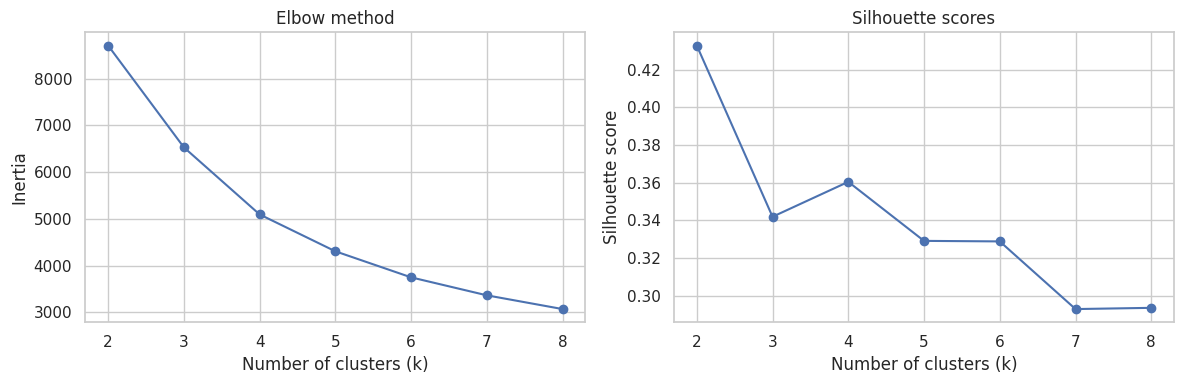

,k,inertia,silhouette
0,2,8710.374,0.433
1,3,6532.362,0.342
2,4,5096.999,0.360
3,5,4307.974,0.329
4,6,3750.534,0.329
5,7,3366.000,0.293
6,8,3071.957,0.293


In [63]:
k_values = list(range(2, 9))
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(features_scaled)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(features_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_values, inertias, marker="o")
axes[0].set(title="Elbow method", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[1].plot(k_values, silhouette_scores, marker="o")
axes[1].set(title="Silhouette scores", xlabel="Number of clusters (k)", ylabel="Silhouette score")
plt.tight_layout()
plt.show()

score_table = pd.DataFrame({"k": k_values, "inertia": inertias, "silhouette": silhouette_scores})
display(score_table.round(3))

In [64]:
best_k = k_values[int(np.argmax(silhouette_scores))]
print("Selected k:", best_k)

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(features_scaled)
print("Final silhouette score:", round(silhouette_score(features_scaled, rfm["Cluster"]), 3))
print(rfm["Cluster"].value_counts().sort_index())

Selected k: 2
Final silhouette score: 0.433
Cluster
0    3506
1    2352
Name: count, dtype: int64


## 8. PCA: reduce 3 RFM dimensions to 2
PCA finds directions of maximum variance in the **scaled, log-transformed** RFM features. These components are for visualization; K-Means was fitted on all three standardized features.

In [65]:
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(features_scaled)
rfm["PC1"] = rfm_pca[:, 0]
rfm["PC2"] = rfm_pca[:, 1]

print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))
print("Total explained variance:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

loadings = pd.DataFrame(pca.components_.T, index=["Recency", "Frequency", "Monetary"], columns=["PC1", "PC2"])
display(loadings.round(3))

Explained variance ratio: [0.755 0.189]
Total explained variance: 94.39 %


,PC1,PC2
Recency,-0.507,0.859
Frequency,0.616,0.302
Monetary,0.603,0.413


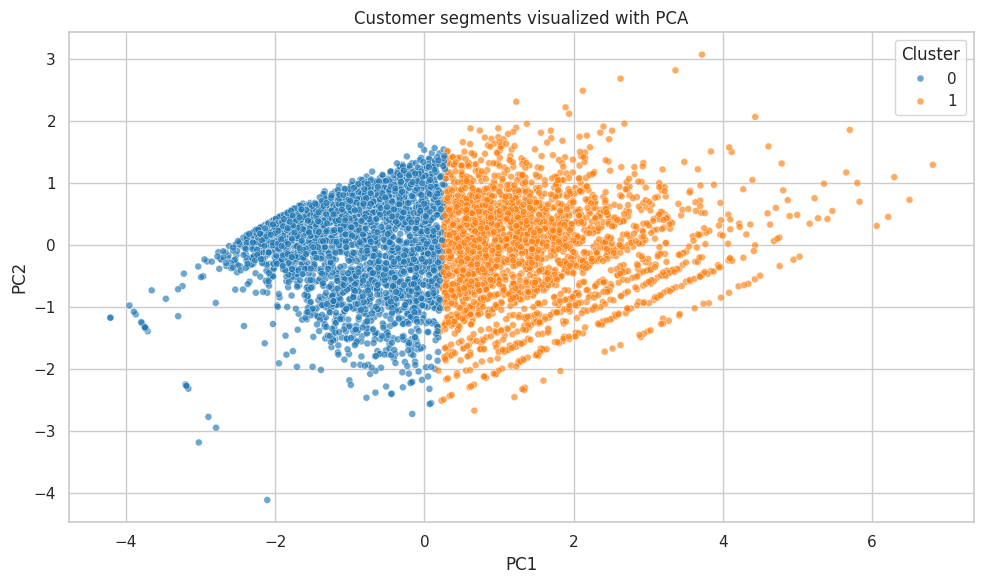

In [66]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=rfm.reset_index(), x="PC1", y="PC2", hue="Cluster", palette="tab10", s=25, alpha=0.65)
plt.title("Customer segments visualized with PCA")
plt.tight_layout()
plt.show()

In [67]:

profile = rfm.groupby("Cluster").agg(
    Customers=("Recency", "size"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean"),
    TotalRevenue=("Monetary", "sum")
)

profile["CustomerSharePct"] = (
    profile["Customers"] / profile["Customers"].sum() * 100
)

profile["RevenueSharePct"] = (
    profile["TotalRevenue"] / profile["TotalRevenue"].sum() * 100
)

median_r = rfm["Recency"].median()
median_f = rfm["Frequency"].median()
median_m = rfm["Monetary"].median()

def assign_persona(row):
    recent = row["AvgRecency"] <= median_r
    frequent = row["AvgFrequency"] > median_f
    high_spend = row["AvgMonetary"] > median_m

    if recent and frequent and high_spend:
        return "Champions", "VIP rewards, early product access, referral offers"
    elif not recent and (frequent or high_spend):
        return "At-risk valuable", "Win-back emails, personalized offers, feedback survey"
    elif recent and high_spend:
        return "High-spending potential", "Cross-sell bundles and loyalty enrollment"
    elif recent and frequent:
        return "Active regulars", "Points program and relevant recommendations"
    elif recent:
        return "Recent / occasional", "Second-purchase incentive and onboarding"
    else:
        return "Dormant / low-engagement", "Low-cost reactivation campaign"

profile[["Persona", "RecommendedAction"]] = profile.apply(
    lambda row: pd.Series(assign_persona(row)),
    axis=1
)

display(
    profile[
        [
            "Customers",
            "CustomerSharePct",
            "AvgRecency",
            "AvgFrequency",
            "AvgMonetary",
            "RevenueSharePct",
            "Persona",
            "RecommendedAction"
        ]
    ].round(2)
)

,Customers,CustomerSharePct,AvgRecency,AvgFrequency,AvgMonetary,RevenueSharePct,Persona,RecommendedAction
Cluster,,,,,,,,
0,3506,59.85,296.7,2.41,577.85,12.37,Dormant / low-engagement,Low-cost reactivation campaign
1,2352,40.15,49.2,15.40,6104.03,87.63,Champions,"VIP rewards, early product access, referral of..."


In [68]:
for cluster, row in profile.iterrows():
    print(f"Cluster {cluster}: {row['Persona']}")
    print(f"  Customers: {int(row['Customers'])} | Average recency: {row['AvgRecency']:.1f} days")
    print(f"  Average orders: {row['AvgFrequency']:.1f} | Average spend: £{row['AvgMonetary']:.2f}")
    print(f"  Revenue share: {row['RevenueSharePct']:.1f}%")
    print(f"  Marketing action: {row['RecommendedAction']}\n")

Cluster 0: Dormant / low-engagement
  Customers: 3506 | Average recency: 296.7 days
  Average orders: 2.4 | Average spend: £577.85
  Revenue share: 12.4%
  Marketing action: Low-cost reactivation campaign

Cluster 1: Champions
  Customers: 2352 | Average recency: 49.2 days
  Average orders: 15.4 | Average spend: £6104.03
  Revenue share: 87.6%
  Marketing action: VIP rewards, early product access, referral offers

